In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy, math

In [2]:
X_train = np.array([
    [1.0, 2.0],
    [1.5, 1.0],
    [2.0, 1.5],
    [2.5, 3.0],
    [3.0, 1.0],
    [3.5, 2.5],
    [4.0, 3.5],
    [1.0, 3.5]
])

y_train = np.array([0, 0, 0, 1, 0, 1, 1, 1])

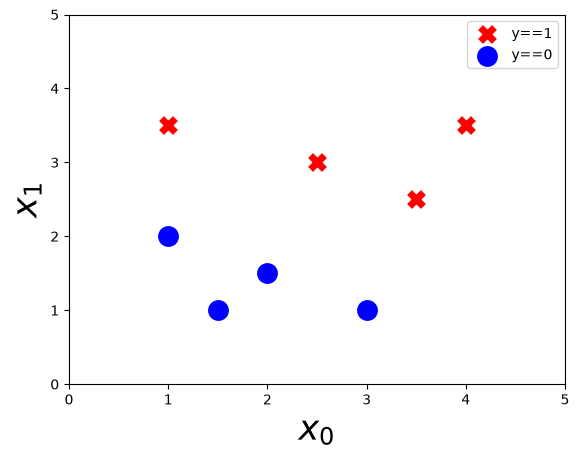

In [3]:
positive = y_train == 1
negative = y_train == 0

plt.scatter(X_train[positive, 0], X_train[positive, 1], c='r', marker='x', s=100, lw=5, label='y==1')
plt.scatter(X_train[negative, 0], X_train[negative, 1], c='b', marker='o', s=100, lw=5, label='y==0')
plt.xlabel('$x_0$', size='25')
plt.ylabel('$x_1$', size='25')
plt.axis([0,5,0,5])
plt.legend()
plt.show()

In [4]:
def sigmoid(z):
    g = 1 / (1 + np.exp(-z))
    return g

In [13]:
def compute_cost(X, y, w, b):
    m = X.shape[0]
    cost = 0
    for i in range(m):
        f_wb = sigmoid(np.dot(X[i],w) + b)
        cost += -y[i] * np.log(f_wb) - (1-y[i]) * np.log(1-f_wb)
    cost /= m
    return cost

In [14]:
# calculate cost at parameters 0
w_in = np.zeros(X_train.shape[1])
b_in = 0

print(f"Cost at given parameters: {compute_cost(X_train, y_train, w_in, b_in)}")

Cost at given parameters: 0.6931471805599453


In [19]:
def compute_gradient(X, y, w, b):
    m,n = X.shape
    dj_dw = np.zeros(n)
    dj_db = 0
    for i in range(m):
        f_wb = sigmoid(np.dot(X[i], w) + b)
        err = f_wb - y[i]
        for j in range(n):
            dj_dw[j] += err * X[i][j]
        dj_db += err
    dj_dw /= m
    dj_db /= m
    return dj_dw, dj_db

In [23]:
def gradient_descent(X, y, w_in, b_in, alpha, num_iters):
    
    hist = dict()
    hist['iteration'] = []
    hist['cost'] = []
    hist['gradients'] = []
    hist['parameters'] = []

    w = w_in
    b = b_in

    for i in range(num_iters):
        
        dj_dw, dj_db = compute_gradient(X, y, w, b)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db

        hist['iteration'].append(i)
        hist['cost'].append(compute_cost(X, y, w, b))
        hist['gradients'].append((dj_dw, dj_db))
        hist['parameters'].append((w, b))

        if i % math.ceil(num_iters / 10) == 0:
            print(
                f"Iteration: {i:4}, Cost: {hist['cost'][-1]:.4f}",
                f"dj_dw: {dj_dw}, dj_db: {dj_db:.4f}",
                f"w: {w}, b: {b:.4f}"
            )
    return w, b, hist

In [46]:
# gradient descent
w_in = np.zeros(X_train.shape[1])
b_in = 0
alpha = 0.1
iterations = 5000
np.set_printoptions(precision=3)

w_out, b_out, hist = gradient_descent(X_train, y_train, w_in, b_in, alpha, iterations)

Iteration:    0, Cost: 0.6723 dj_dw: [-0.219 -0.438], dj_db: 0.0000 w: [0.022 0.044], b: 0.0000
Iteration:  500, Cost: 0.2304 dj_dw: [-0.008 -0.014], dj_db: 0.0512 w: [0.126 1.744], b: -3.8570
Iteration: 1000, Cost: 0.1419 dj_dw: [-0.005 -0.009], dj_db: 0.0315 w: [0.447 2.287], b: -5.8431
Iteration: 1500, Cost: 0.1024 dj_dw: [-0.003 -0.007], dj_db: 0.0227 w: [0.654 2.667], b: -7.1740
Iteration: 2000, Cost: 0.0800 dj_dw: [-0.003 -0.005], dj_db: 0.0178 w: [0.805 2.96 ], b: -8.1768
Iteration: 2500, Cost: 0.0656 dj_dw: [-0.002 -0.004], dj_db: 0.0146 w: [0.925 3.198], b: -8.9814
Iteration: 3000, Cost: 0.0555 dj_dw: [-0.002 -0.004], dj_db: 0.0124 w: [1.024 3.398], b: -9.6532
Iteration: 3500, Cost: 0.0481 dj_dw: [-0.002 -0.003], dj_db: 0.0107 w: [1.108 3.571], b: -10.2296
Iteration: 4000, Cost: 0.0425 dj_dw: [-0.001 -0.003], dj_db: 0.0095 w: [1.181 3.723], b: -10.7343
Iteration: 4500, Cost: 0.0380 dj_dw: [-0.001 -0.003], dj_db: 0.0085 w: [1.246 3.859], b: -11.1830


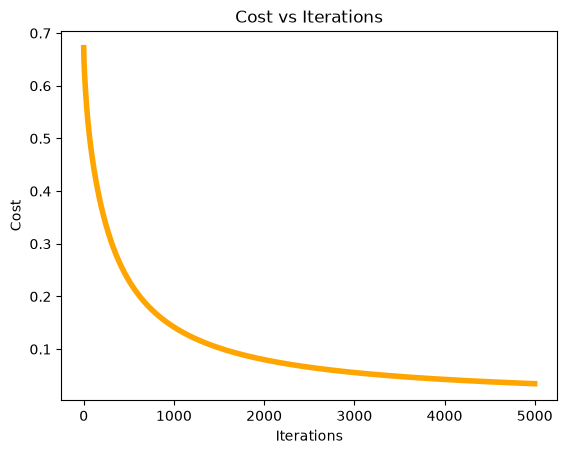

In [47]:
# cost vs iteration
plt.plot(hist['iteration'], hist['cost'], lw=4, c='orange')
plt.xlabel('Iterations')
plt.ylabel('Cost')
plt.title('Cost vs Iterations')
plt.show()

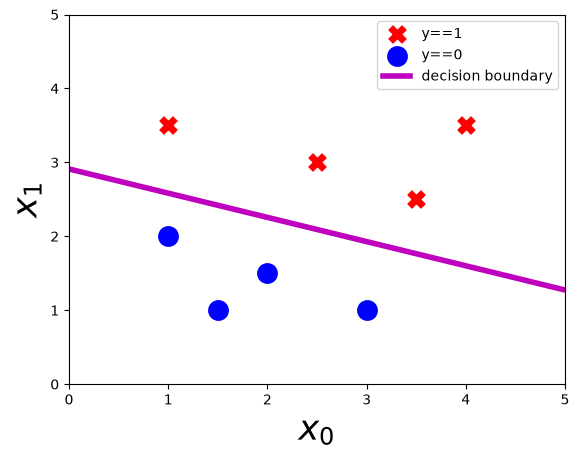

In [48]:
# plot data
positive = y_train == 1
negative = y_train == 0

plt.scatter(X_train[positive, 0], X_train[positive, 1], c='r', marker='x', s=100, lw=5, label='y==1')
plt.scatter(X_train[negative, 0], X_train[negative, 1], c='b', marker='o', s=100, lw=5, label='y==0')
plt.xlabel('$x_0$', size='25')
plt.ylabel('$x_1$', size='25')
plt.axis([0,5,0,5])

# plot decision boundary -> where g(w.x+b) = 0.5 -> where w.x + b = 0 -> w0*x0 + w1*x1 + b = 0
x0 = -b_out / w_out[0] # x0 intercept
x1 = -b_out / w_out[1] # x1 intercept
# two points we got (0,x1), (x0, 0)

plt.plot([0,x0],[x1,0], c='m', lw=4, label='decision boundary')

plt.legend()
plt.show()